>**Colab Computer Vision Tutorial 03** created by [Jooyeon Lee](http://leejooyeon.com/) | Check out other colab codes on [GITHUB](https://github.com/ganadaralabs/ComputerVision_Colab)


#실습3_**이미지프로세싱**의 기초2

##01 스레시홀딩(Thresholding, 임계처리)

- 사진의 각각의 픽셀을 경계값을 기준으로 두 그룹으로 나누어 바이너리 이미지를 만드는 방법
  - e.g. 이미지의 각각의 픽셀의 값이 경계값을 넘지 못하면 0, 넘으면 설정한 최대값으로 값을 반환
- 이미지 속 객체의 모양과 경계선을 좀 더 명확하게 판단하기 위해서 바이너리 이미지로 만듦
- 스레시홀딩은 그레이스케일 이미지를 사용



**01.1 기본 스레시홀딩(Simple Thresholding)**

`retVal, result = cv2.threshold(sourceImage, threshVal, maxVal, thresholdType)`

Parameters:
- retVal - 스레시홀딩에 사용한 경계값을 반환
- result - 스레시홀딩 이미지 결과값
- sourceImage – 스레시홀딩을 할 이미지
- threshVal - 스레시홀딩에 사용한 경계값
- maxVal - 경계값을 넘을 때 매기는 임의의 값
- thresholdType - 스레시홀딩 타입
  - cv.THRESH_BINARY
  - cv.THRESH_BINARY_INV
  - cv.THRESH_TRUNC
  - cv.THRESH_TOZERO
  - cv.THRESH_TOZERO_INV


<br>

[Original Value] | [cv.THRESH_BINARY] | [cv.THRESH_BINARY_INV]
-                |     -              |            -
![original](https://docs.opencv.org/3.4/Threshold_Tutorial_Theory_Base_Figure.png)| ![cv.THRESH_BINARY](https://docs.opencv.org/3.4/Threshold_Tutorial_Theory_Binary.png) | ![cv.THRESH_BINARY_INV](https://docs.opencv.org/3.4/Threshold_Tutorial_Theory_Binary_Inverted.png)




[cv.THRESH_TRUNC] | [cv.THRESH_TOZERO] | [cv.THRESH_TOZERO_INV]
        -         |          -         |            -
![cv.THRESH_TRUNC](https://docs.opencv.org/3.4/Threshold_Tutorial_Theory_Truncate.png) | ![cv.THRESH_TOZERO](https://docs.opencv.org/3.4/Threshold_Tutorial_Theory_Zero.png) | ![cv.THRESH_TOZERO_INV](https://docs.opencv.org/3.4/Threshold_Tutorial_Theory_Zero_Inverted.png)


<br>

**참고자료:**

- [Basic Thresholding Operations](https://docs.opencv.org/3.4/db/d8e/tutorial_threshold.html)
- [Image Thresholding](https://docs.opencv.org/master/d7/d4d/tutorial_py_thresholding.html)

<br>


**01.2 기본 스레시홀딩 옵션 비교하기**

In [ ]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


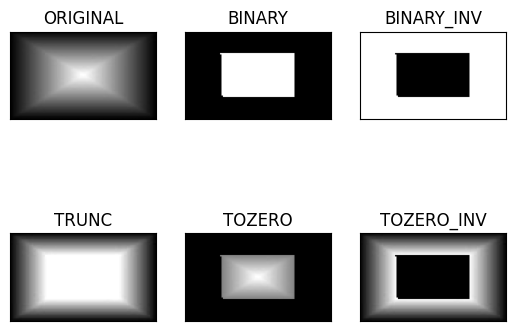

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
from matplotlib import pyplot as plt

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/gradient_rectangular.jpg', cv2.IMREAD_GRAYSCALE)

retVal,thresh1 = cv2.threshold(image,127,255,cv2.THRESH_BINARY)
retVal,thresh2 = cv2.threshold(image,127,255,cv2.THRESH_BINARY_INV)
retVal,thresh3 = cv2.threshold(image,127,255,cv2.THRESH_TRUNC)
retVal,thresh4 = cv2.threshold(image,127,255,cv2.THRESH_TOZERO)
retVal,thresh5 = cv2.threshold(image,127,255,cv2.THRESH_TOZERO_INV)

imageList = {'ORIGINAL':image,'BINARY':thresh1,'BINARY_INV':thresh2,'TRUNC':thresh3,'TOZERO':thresh4,'TOZERO_INV':thresh5}

for i, (key,value) in enumerate(imageList.items()):
  plt.subplot(2,3,i+1)
  plt.imshow(value, cmap='gray')
  plt.xticks([]),plt.yticks([])
  plt.title(key)

plt.savefig("figure1", transparent=True)
plt.show()

**01.3 다양한 경계값에 따른 스레시홀딩 이미지**

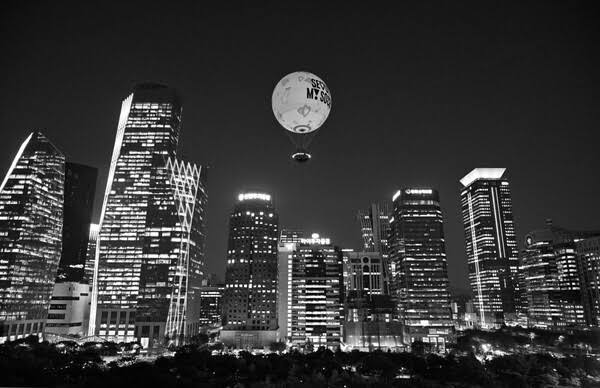

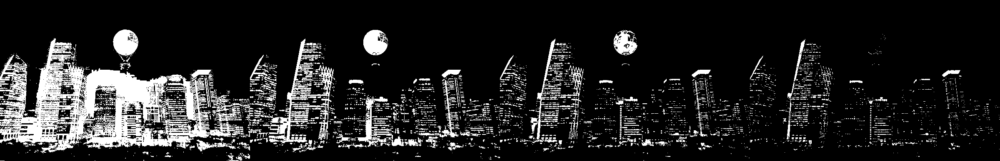

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

imagePath ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/야경.jpg'
grayImage = cv2.imread(imagePath, cv2.IMREAD_GRAYSCALE)

_, thresh1 = cv2.threshold(grayImage, 50, 255, cv2.THRESH_BINARY)
_, thresh2 = cv2.threshold(grayImage, 100, 255, cv2.THRESH_BINARY)
_, thresh3 = cv2.threshold(grayImage, 150, 255, cv2.THRESH_BINARY)
_, thresh4 = cv2.threshold(grayImage, 200, 255, cv2.THRESH_BINARY)


cv2_imshow(grayImage)
mask_frame = cv2.hconcat([thresh1, thresh2, thresh3, thresh4])
cv2_imshow(mask_frame)



**01.4 오츠의 이진화 알고리즘(Otsu's Binarization)**

오츠 노부유키(1979년) - 이미지에 따라 최적화된 경계값을 찾을 때 반복적인 시도 없이 한 번에 임계값을 찾을 수 있는 방법을 고안




OTSU: 102.0


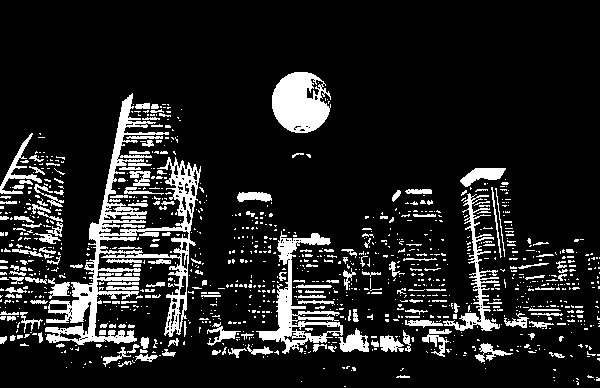

In [ ]:
retVal, otsuImage = cv2.threshold(grayImage, 0, 255, cv2.THRESH_OTSU)

print("OTSU:", retVal)
cv2_imshow(otsuImage)

**01.5 적응형 스레시홀딩(Adaptive thresholding)**

일반 쓰레시홀딩은 전체에 대한 임계값, 적응형은 부분부분으로 나누에 각각의 임계값을 설정한다.

`result = cv2.adaptiveThreshold(sourceImage, maxVal, adaptiveMethod,thresholdType, blockSize, C)`


Parameters:
- result - 스레시홀딩 이미지 결과값
- sourceImage – 스레시홀딩을 할 이미지
- maxVal - 경계값을 넘을 때 매기는 임의의 값
- adaptiveMethod - 경계값을 자동을 결정하는 방법
  - cv.ADAPTIVE_THRESH_MEAN_C : 이웃픽셀의 평균으로 결정; 경계값은 기준 픽셀(x,y)의 이웃한 픽셀(blockSize x blockSize)평균에 C 상수를 뺀 값
  - cv.ADAPTIVE_THRESH_GAUSSIAN_C : 가우시안 분포에 따른 가중치의 합; 경계값은 기준 픽셀(x,y)의 이웃한 픽셀(blockSize x blockSize) 가우시안 가중치 평균에 C 상수를 뺀 값
- thresholdType - 스레시홀딩 타입
  - cv.THRESH_BINARY
  - cv.THRESH_BINARY_INV
- blockSize - 이웃한 픽셀영역의 크기 (3,5,7,...) 홀수로 지정해야함(기준픽셀을 포함하기때문).
- C - 이웃 픽셀의 평균 혹은 가중치 합에서 가감할 상수(보통은 자연수를 사용하지만 0과 음수도 사용가능)



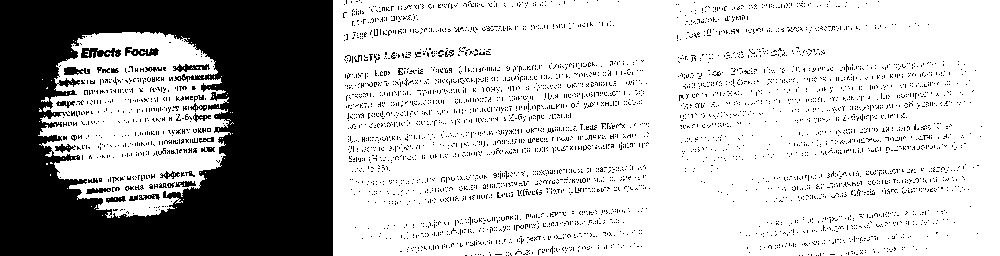

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

imagePath ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/scannedImage.jpg'
grayImage = cv2.imread(imagePath, cv2.IMREAD_GRAYSCALE)

ret,thresh127 = cv2.threshold(grayImage,127,255,cv2.THRESH_BINARY)
adaptiveMean = cv2.adaptiveThreshold(grayImage,255,cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY,7,7)
adaptiveGaussian = cv2.adaptiveThreshold(grayImage,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,7,7)

adaptive = cv2.hconcat([thresh127, adaptiveMean, adaptiveGaussian])
cv2_imshow(adaptive)

In [ ]:
adaptiveMean1 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 3, 5)
adaptiveMean2 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 5, 5)
adaptiveMean3 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 7, 5)
adaptiveMean4 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 9, 5)
adaptiveMean5 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 5)
adaptiveMean6 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 13, 5)

adaptiveMeanImages1 = cv2.hconcat([adaptiveMean1, adaptiveMean2, adaptiveMean3])
adaptiveMeanImages2 = cv2.hconcat([adaptiveMean4, adaptiveMean5, adaptiveMean6])
adaptiveMeanImages = cv2.vconcat([adaptiveMeanImages1, adaptiveMeanImages2])

cv2_imshow(adaptiveMeanImages)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
adaptiveGaussian1 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 3, 5)
adaptiveGaussian2 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 5, 5)
adaptiveGaussian3 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 7, 5)
adaptiveGaussian4 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 9, 5)
adaptiveGaussian5 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 5)
adaptiveGaussian6 = cv2.adaptiveThreshold(grayImage, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 13, 5)

adaptiveGaussianImages1 = cv2.hconcat([adaptiveGaussian1, adaptiveGaussian2, adaptiveGaussian3])
adaptiveGaussianImages2 = cv2.hconcat([adaptiveGaussian4, adaptiveGaussian5, adaptiveGaussian6])

adaptiveGaussianImages = cv2.vconcat([adaptiveGaussianImages1, adaptiveGaussianImages2])
cv2_imshow(adaptiveGaussianImages)

Output hidden; open in https://colab.research.google.com to view.

**01.6 컬러 이미지 스레시홀딩**

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from google.colab.patches import cv2_imshow


imagePath ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/flowers.jpg'
img = cv2.imread(imagePath)

ret, thresh1 = cv2.threshold(img,127,255, cv2.THRESH_BINARY)
ret, thresh2 = cv2.threshold(img,127,255, cv2.THRESH_BINARY_INV)
ret, thresh3 = cv2.threshold(img,127,255, cv2.THRESH_TRUNC)
ret, thresh4 = cv2.threshold(img,127,255, cv2.THRESH_TOZERO)
ret, thresh5 = cv2.threshold(img,127,255, cv2.THRESH_TOZERO_INV)

cv2_imshow(img,)
image_frame = cv2.hconcat([thresh1,thresh2,thresh3,thresh4,thresh5])
cv2_imshow(image_frame)

Output hidden; open in https://colab.research.google.com to view.

##02 이미지연산

uint8 데이터 타입을 가지고 있는 두 NumPy 색상 배열을 0-255 범위 안에서 OpenCV나 NumPy를 사용하여 사칙연산


<br>


**Numpy** | **OpenCV**
    -     |      -
a+b       | cv2.add(a,b)   
a-b       | cv2.subtract(a,b)
a*b       | cv2.multiply(a,b)
a/b       | cv2.divide(a,b)


<br>

- 두 이미지를 곱하거나 나누는 연산은 잘 사용하지 않음
- OpenCV와 NumPy연산의 차이점:

  1. **OpenCV 사용** - *클리핑(clipping)*: OpenCV는 픽셀 범위 값이 255를 넘으면 값을 클리핑(clipping)해서 255를 유지
    - **cv2.add**(np.uint8([200]), np.uint8([100]))는 200+100= 300이지만 **255가 최대**
    - **cv2.subtract**(np.uint8([50]), np.uint8([100]))는  50-100= -50이지만 **0이 최소**

  2. **Numpy 사용** - *랩어라운드(wrap around)*: NumPy는 225가 넘으면 남은 값을 0부터 다시 더해주기(wraps around) 때문에 255을 뺀 값에서 1을 더 뺌 (0부터 시작)
    - np.uint8([200]) + np.uint8([100])는 *200+100= 300*이지만 300-256=**44가 최대**
    - np.uint8([50]) - np.uint8([100])는 *50-100= -50*이지만 256-50=**206이 최소**



<br>




**참고자료:**
- [When OpenCV hconcat gives an error for some reason](https://memotut.com/when-opencv-hconcat-gives-an-error-for-some-reason-82de8/)


**02.1 Numpy와 OpenCV의 연산비교**

In [ ]:
import numpy as np
import cv2

a = np.uint8([[10,200,50]])
b = np.uint8([[250,100,100]])

addCV = cv2.add(a,b)
subCV = cv2.subtract(a,b)
mulCV = cv2.multiply(a,3)
divCV = cv2.divide(a,3)

addNP = a+b
subNP = a-b
mulNP = a*3
divNP = a/3

print("CV: ",addCV, subCV, mulCV, divCV)
print("NP: ",addNP, subNP, mulNP, divNP)

CV:  [[255 255 150]] [[  0 100   0]] [[ 30 255 150]] [[ 3 67 17]]
NP:  [[  4  44 150]] [[ 16 100 206]] [[ 30  88 150]] [[ 3.33333333 66.66666667 16.66666667]]


**02.2 이미지 연산**

In [ ]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


원본 이미지


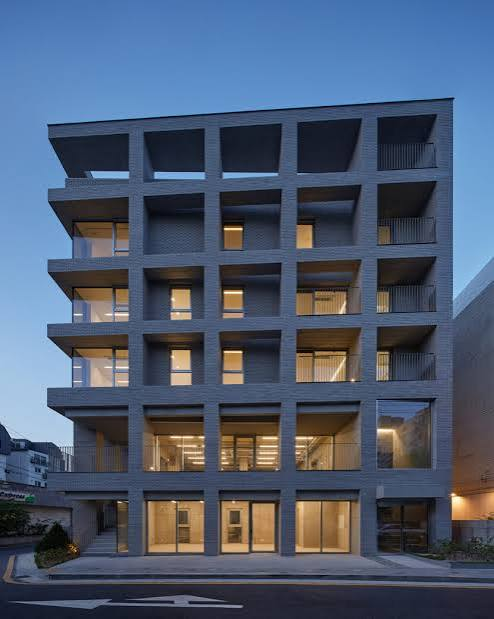

CV: Add, Sub, Mul, Div


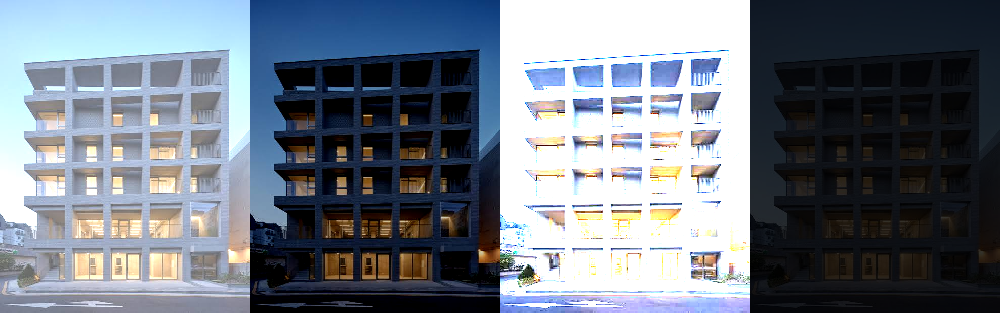

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/건물.jpg' #이미지의 위치로 변경
image = cv2.imread(imagePath).astype(np.uint8)

print("원본 이미지")
cv2_imshow(image)

#이미지와 같은 사이즈의 Numpy 배열을 만들고, 100와 50으로 채움
add100 = np.full(image.shape, 100, np.uint8)
subtract50 = np.full(image.shape, 50, np.uint8)
multiply5 = np.full(image.shape, 5, np.uint8)
divide5 = np.full(image.shape, 5, np.uint8)

#CV 이미지 연산
addCV = cv2.add(image, add100)
subtractCV = cv2.subtract(image, subtract50)
multiplyCV = cv2.multiply(image, multiply5)
divideCV = cv2.divide(image, divide5)

CV_frame = cv2.hconcat([addCV,subtractCV,multiplyCV,divideCV])
print("CV: Add, Sub, Mul, Div")
cv2_imshow(CV_frame)

uint8 uint8 uint8 float64
uint8 uint8 uint8 uint8
NP: Add, Sub, Mul, Div


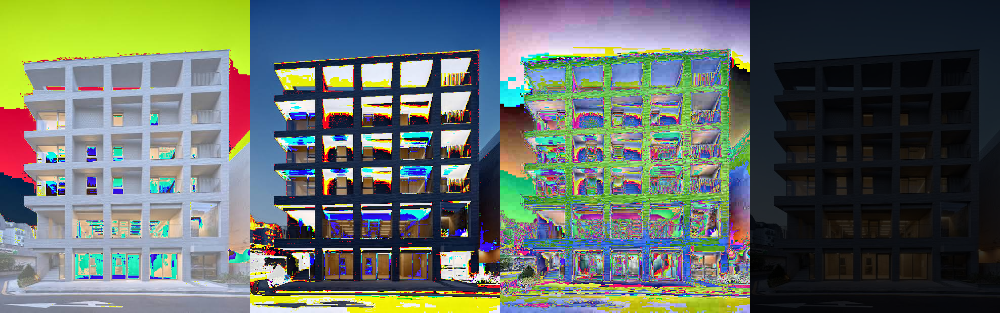

In [ ]:
#NP 이미지 연산
addNP = image + add100
subtractNP = image - subtract50
multiplyNP = image * multiply5
divideNP = image / divide5

#cv2.hconcat오류해결: 소수점을 정수 uint8 자료형으로 변환
print(subtractNP.dtype, addNP.dtype, multiplyNP.dtype, divideNP.dtype)
divideNP = divideNP.astype('uint8')
print(subtractNP.dtype, addNP.dtype, multiplyNP.dtype, divideNP.dtype)


NP_frame = cv2.hconcat([addNP,subtractNP,multiplyNP,divideNP])
print("NP: Add, Sub, Mul, Div")
cv2_imshow(NP_frame)

In [ ]:
Compare_frame = cv2.vconcat((CV_frame,NP_frame))
print("Add, Sub, Mul, Div")
cv2_imshow(Compare_frame)

cv2.imwrite("CV_image.jpg", CV_frame)
cv2.imwrite("NP_image.jpg", NP_frame)

Output hidden; open in https://colab.research.google.com to view.

**02.3 두 이미지 합과 차**

In [ ]:
def match_image_sizes(img1, img2):
    """
    img1을 기준으로 img2의 가로·세로 크기 및 채널을 맞춘 뒤,
    규격이 통일된 두 이미지를 각각 반환합니다.
    """
    # 1. 기준 이미지(img1)의 세로(h), 가로(w) 크기 가져오기
    h1, w1 = img1.shape[:2]

    # 2. img2를 img1의 크기와 똑같이 리사이즈
    img2_resized = cv2.resize(img2, (w1, h1))

    # 3. 채널 수(컬러/흑백) 일치시키기
    if len(img1.shape) != len(img2_resized.shape):
        if len(img1.shape) == 2:  # img1이 흑백인 경우
            img1 = cv2.cvtColor(img1, cv2.COLOR_GRAY2BGR)
        if len(img2_resized.shape) == 2:  # img2가 흑백인 경우
            img2_resized = cv2.cvtColor(img2_resized, cv2.COLOR_GRAY2BGR)

    # 4. 규격이 맞춰진 두 이미지를 각각 반환
    return img1, img2_resized

(388, 600, 3)
(641, 1140, 3)
원본 이미지


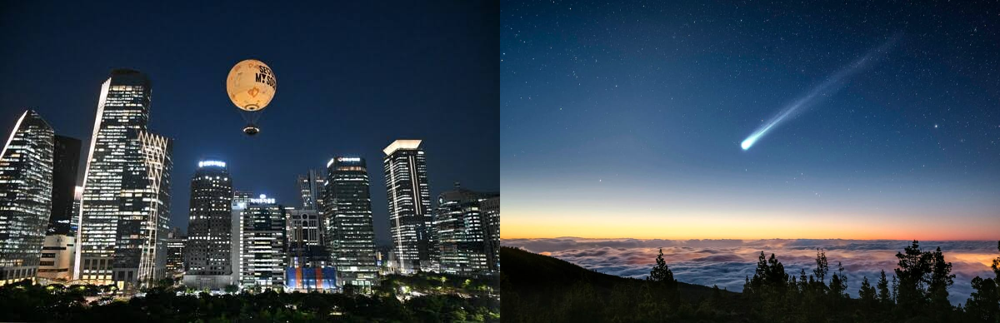

CV: Add, Sub
NP: Add, Sub


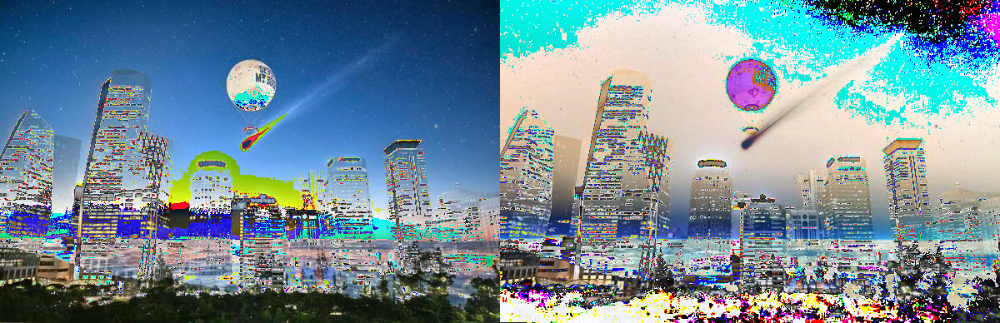

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/야경.jpg'
imagePath2 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/혜성.jpg'
image1 = cv2.imread(imagePath1)
image2 = cv2.imread(imagePath2)

print(image1.shape)
print(image2.shape)

image1, image2 = match_image_sizes(image1, image2)

print("원본 이미지")
# cv2.hconcat()은 세로 이미지의 길이가 같아야 한다.
image_frame = cv2.hconcat([image1,image2])
cv2_imshow(image_frame)


#OpenCV 연산
CVaddImages = cv2.add(image1,image2)
CVsubImages = cv2.subtract(image1,image2)

print("CV: Add, Sub")
# CVimage_frame = cv2.hconcat([CVaddImages,CVsubImages])
# cv2_imshow(CVimage_frame)


#Nympy 연산
NPaddImages = image1+image2
NPsubImages = image1-image2

print("NP: Add, Sub")
NPimage_frame = cv2.hconcat([NPaddImages,NPsubImages])
cv2_imshow(NPimage_frame)

**02.4 가중치 블랜딩**

`cv2.addWeighted(image1,alpha,image2, beta, gamma)`

Parameters:
- alpha: image1에 지정할 가중치
- beta: image2 지정할 가중치 (보통 1-alpha 적용)
- gamma: 연산결과에 가감할 상수 (보통 0 적용)

사진1, 사진2, 가중치 블랜딩, 직접구현


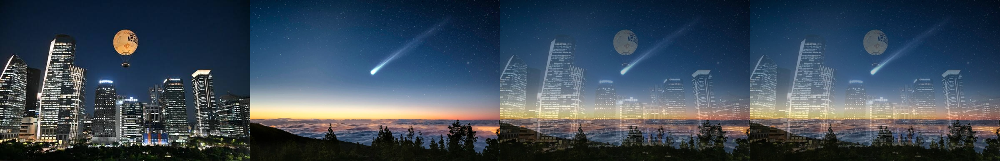

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/야경.jpg'
imagePath2 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/혜성.jpg'
image1 = cv2.imread(imagePath1)
image2 = cv2.imread(imagePath2)

# 만들어 놓은 함수 적용
image1, image2 = match_image_sizes(image1, image2)

alpha = 0.3

#가중치 블랜딩 함수
dst = cv2.addWeighted(image1,alpha,image2,(1-alpha),0)

#직접 연산
blended = image1*alpha + image2*(1-alpha)
blended = blended.astype(np.uint8)

print("사진1, 사진2, 가중치 블랜딩, 직접구현")
Weighted_frame = cv2.hconcat([image1,image2,dst,blended])
cv2_imshow(Weighted_frame)

**02.5 이미지의 뺄셈연산과 차이미지(image differencing)**
- 이미지를 OpenCV나 Numpy 뺼셈 연산을 하면 두 이미지를 어떤 순서로 빼느냐에 따라 결과가 달라짐


- **차이미지(image differencing)**: 두 이미지의 차를 절대값으로 변환해 반영하면 순서가 달라도 결과는 같음
  ```
  cv2.absdiff(image1,image2)
  ```
- 뺼셈 연산을 이용하면 두 개의 영상에서
변화가 있는 영역을 쉽게 찾을 수 있음
  - 움직이는 영역에서만 픽셀 값 차이가 두드러지게 나타남
  - 두 입력 영상에서 큰 변화가 없는 영역은 픽셀 값이 0에
가까운 검은색으로 채워지게 됨
  


In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/야경.jpg'
imagePath2 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/혜성.jpg'
image1 = cv2.imread(imagePath1)
image2 = cv2.imread(imagePath2)

# 1. 기준이 될 image1의 가로(width), 세로(height) 크기를 가져옵니다.
# shape은 (세로, 가로, 채널) 순서로 값을 반환합니다.
h1, w1 = image1.shape[:2]

# 2. image2의 크기를 image1의 가로, 세로 크기와 똑같이 리사이즈합니다.
# (주의: cv2.resize에서는 크기를 지칭할 때 (가로, 세로) 순서로 넣어야 합니다.)
image2_resized = cv2.resize(image2, (w1, h1))

# 3. 만약 두 이미지의 채널(컬러/흑백) 정보가 다를 경우를 대비해 타입을 맞춰줍니다.
if len(image1.shape) != len(image2_resized.shape):
    if len(image1.shape) == 2:  # image1이 흑백인 경우 컬러로 변환
        image1 = cv2.cvtColor(image1, cv2.COLOR_GRAY2BGR)
    if len(image2_resized.shape) == 2:  # image2가 흑백인 경우 컬러로 변환
        image2_resized = cv2.cvtColor(image2_resized, cv2.COLOR_GRAY2BGR)
image2 = image2_resized

#뺼셈 연산
print("image1, image2, subtract(img1,img2), subtract(img2,img1) ")
diff1 = cv2.subtract(image1,image2)
diff2 = cv2.subtract(image2,image1)

image_frame = cv2.hconcat([image1,image2,diff1,diff2])
cv2_imshow(image_frame)

print("\n")

#절대값 차이
print("image1, image2, absdiff(img1,img2), absdiff(img2,img1) ")
absDiff1 = cv2.absdiff(image1,image2)
absDiff2 = cv2.absdiff(image2,image1)

image_frame = cv2.hconcat([image1,image2,absDiff1,absDiff2])
cv2_imshow(image_frame)

Output hidden; open in https://colab.research.google.com to view.

**02.6 차이미지와 스레시홀딩을 사용해 틀린그림 찾기I**

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/diff1.jpg'
imagePath2 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/diff2.jpg'

#RGB 색상 이미지
image1 = cv2.imread(imagePath1)
image2 = cv2.imread(imagePath2)

#RGB 색상 이미지 차
imageDiff = cv2.absdiff(image1,image2)
_, imageDiff_t = cv2.threshold(imageDiff, 10, 255, cv2.THRESH_BINARY)

image_frame = cv2.hconcat([image1,image2,imageDiff])
cv2_imshow(image_frame)
cv2_imshow(imageDiff_t)


Output hidden; open in https://colab.research.google.com to view.

**02.7 비트와이즈 연산(bitwise-operation)**

- OpenCV는 두 이미지의 각 픽셀에 대한 비트단위의 바이너리 연산 기능을 제공
- 두 이미지를 합성할 때 특정 영역만 선택하거나 특정영역만 제외하는 등 선별적인 연산에 도움
- 두 이미지는 동일한 shape을 가지고 있어야 함


1. **AND**: 비교하는 두 픽셀이 모두 0보다 크면 true를 반환
  - `cv2.bitwise_and(image1,image2)`
2. **OR**: 비교하는 두 픽셀 중에 한 픽셀이 0보다 크거나 둘 다 0보다 크면 true를 반환
  - `cv2.bitwise_or(image1,image2)`
3. **XOR**: 비교하는 두 픽셀 중에 한 픽셀이 0보다 크고 두 픽셀이 동시에 0보다 크지 않을 때 true를 반환 (Exclusive OR operation)
  - `cv2.bitwise_xor(image1,image2)`
4. **NOT**: 하나의 이미지를 0이면 true를, 0이 아니면 false를 반환 (바이너리 이미지 반전효과)
  - `cv2.bitwise_not(image1)`

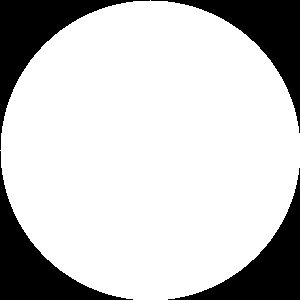

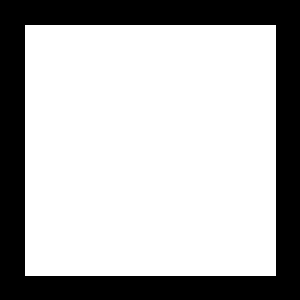

사각형과 원 이미지


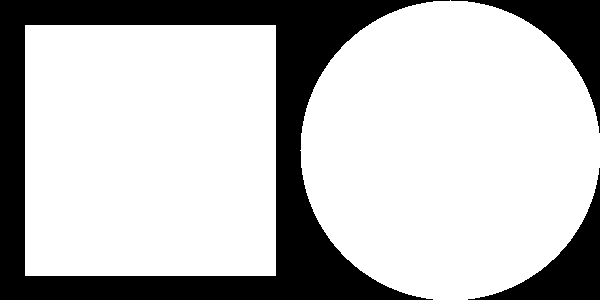

비트와이즈 연산: And, Or, Xor, Not


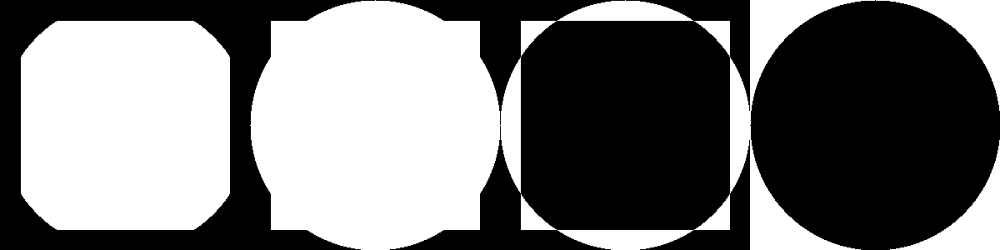

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

#사각형 이미지 생성
rectangle = np.zeros((300, 300), dtype = "uint8")
cv2.rectangle(rectangle, (25, 25), (275, 275), 255, -1)

#원 이미지 생성
circle = np.zeros((300, 300), dtype = "uint8")
cv2.circle(circle, (150, 150), 150, 255, -1)

cv2_imshow(circle)
cv2_imshow(rectangle)

print("사각형과 원 이미지")
shape_frame = cv2.hconcat([rectangle,circle])
cv2_imshow(shape_frame)

#비트와이즈 연산
bitwiseAnd = cv2.bitwise_and(circle,rectangle)
bitwiseOr = cv2.bitwise_or(circle,rectangle)
bitwiseXor = cv2.bitwise_xor(circle,rectangle)
bitwiseNot = cv2.bitwise_not(circle)

print("비트와이즈 연산: And, Or, Xor, Not")
bitwise_frame = cv2.hconcat([bitwiseAnd,bitwiseOr,bitwiseXor,bitwiseNot])
cv2_imshow(bitwise_frame)

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 = '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/건물.jpg'
imagePath2 = '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/야경.jpg'
image1 = cv2.imread(imagePath1)
image2 = cv2.imread(imagePath2)

image1 ,image2 = match_image_sizes(image1, image2)

print("원본 이미지")
image_frame = cv2.hconcat([image1, image2])
cv2_imshow(image_frame)

#마스크 옵션을 사용할 경우, 마스크 이미지 위의 픽셀만 확인한다.
andImage = cv2.bitwise_and(image1, image2)
orImage = cv2.bitwise_or(image1, image2)
xorImage = cv2.bitwise_xor(image1, image2)
notImage1 = cv2.bitwise_not(image1)
notImage2 = cv2.bitwise_not(image2)

print("AND, OR, XOR, NOT")
mask_frame = cv2.hconcat([andImage,orImage,xorImage,notImage1,notImage2])
cv2_imshow(mask_frame)


Output hidden; open in https://colab.research.google.com to view.

**02.8 차이미지와 비트연산자를 사용해 틀린그림 찾기II**

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/diff1.jpg'
imagePath2 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/diff2.jpg'

#RGB 색상 이미지
image1 = cv2.imread(imagePath1)
image2 = cv2.imread(imagePath2)

#RGB 색상 이미지를 그레이스케일로 변환
grayImage1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
grayImage2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

#그레이스케일 이미지 차
imageDiff = cv2.absdiff(grayImage1, grayImage2)
_, imageDiff = cv2.threshold(imageDiff, 10, 255, cv2.THRESH_BINARY)
colorDiff = cv2.cvtColor(imageDiff, cv2.COLOR_GRAY2BGR)
colorDiff[:,:,:2] = 0
spot = cv2.bitwise_or(image1, colorDiff)

grayImage_frame = cv2.hconcat([grayImage1,grayImage2,imageDiff])
cv2_imshow(grayImage_frame)

cv2_imshow(colorDiff)
cv2_imshow(spot)

Output hidden; open in https://colab.research.google.com to view.

##03 이미지 마스크(Image Mask)

하나의 이미지에서 원하는 영역만 때어 내기 위해 **마스크(Mask)**를 사용
- **마스크(mask)**는 바이너리 이미지로, 특정 이미지에서 0이 아닌 픽셀만 따로 연산할 수 있도록 함
- 이미지 연산함수(덧셈과 뺄셈)와 비트와이즈 연산 옵션에 mask 옵션을 추가해 사용
  - **cv2.add**(image1, image2, **mask**=maskImage)
  - **cv2.subtract**(image1, image2, **mask**=maskImage)
  - **cv2.bitwise_and**(image1, image2, **mask**=maskImage)
  - **cv2.bitwise_or**(image1, image2, **mask**=maskImage)
  - **cv2.bitwise_xor**(image1, image2, **mask**=maskImage)
  -**cv2.bitwise_not**(image1, **mask**=maskImage)




2D 마스크 그림


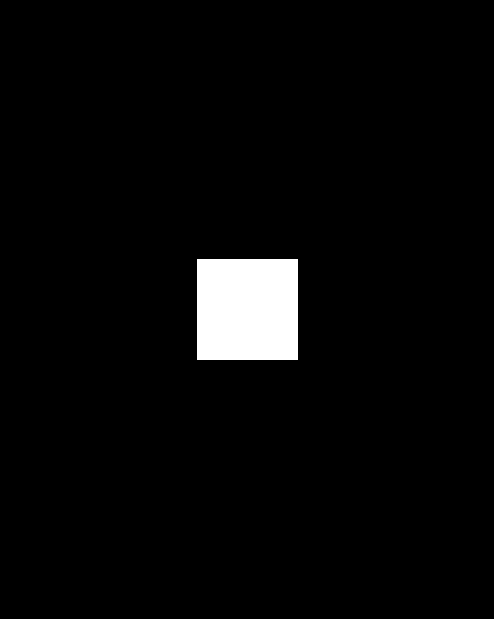

원본 이미지


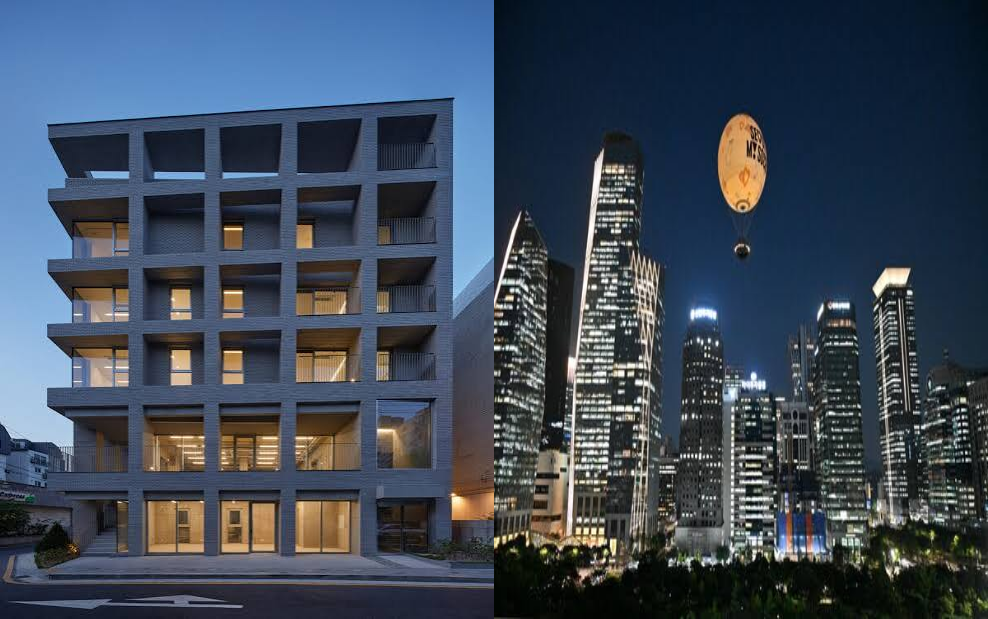

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 = '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/건물.jpg'
imagePath2 = '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/야경.jpg'
image1 = cv2.imread(imagePath1)
image2 = cv2.imread(imagePath2)

image1, image2 = match_image_sizes(image1, image2)


#비트와이즈 2D 마스크 만들기
maskImage2D = np.zeros(image1.shape[:2], np.uint8)
(centerX, centerY) = (image1.shape[1]//2, image1.shape[0]//2)
cv2.rectangle(maskImage2D,(centerX-50, centerY-50),(centerX+50,centerY+50),255,-1)

print("2D 마스크 그림")
cv2_imshow(maskImage2D)

print("원본 이미지")
image_frame = cv2.hconcat([image1, image2])
cv2_imshow(image_frame)


두 이미지의 OpenCV의 덧셈,뺄셈과 마스크 효과를 추가한 이미지


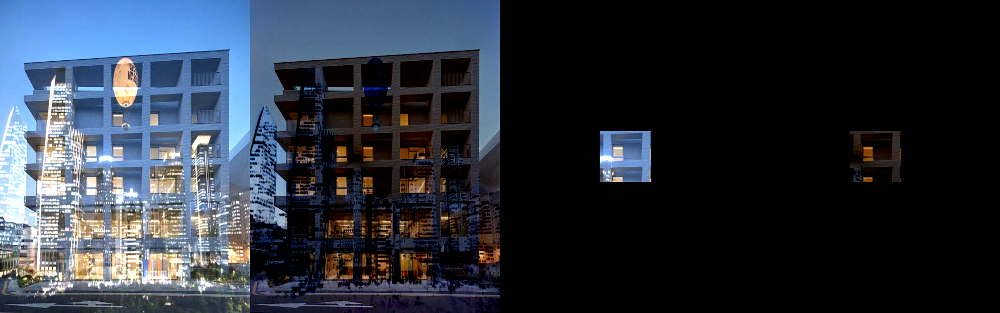

In [ ]:
#두 이미지의 OpenCV 덧셈,뺼셈
addImage = cv2.add(image1, image2)
subImage = cv2.subtract(image1, image2)

#두 이미지의 마스크를 사용한 OpenCV 덧셈,뺄셈
addMask = cv2.add(image1, image2, mask=maskImage2D)
subMask = cv2.subtract(image1, image2, mask=maskImage2D)

print("두 이미지의 OpenCV의 덧셈,뺄셈과 마스크 효과를 추가한 이미지")
mask_frame = cv2.hconcat([addImage, subImage, addMask, subMask])
cv2_imshow(mask_frame)

In [ ]:
#두 이미지의 비트와이즈 AND,OR,XOR 연산
andImage = cv2.bitwise_and(image1, image2)
orImage = cv2.bitwise_or(image1, image2)
xorImage = cv2.bitwise_xor(image1, image2)

#두 이미지의 비트와이즈 AND,OR,XOR 연산에 마스크 추가
andMask = cv2.bitwise_and(image1, image2, mask=maskImage2D)
orMask = cv2.bitwise_or(image1, image2, mask=maskImage2D)
xorMask = cv2.bitwise_xor(image1, image2, mask=maskImage2D)

print("2D 마스크 효과 이미지")
image_frame = cv2.hconcat([andImage,orImage,xorImage])
mask_frame = cv2.hconcat([andMask,orMask,xorMask])
result_frame = cv2.vconcat([image_frame,mask_frame])
cv2_imshow(result_frame)

Output hidden; open in https://colab.research.google.com to view.

2D 마스크 효과 이미지


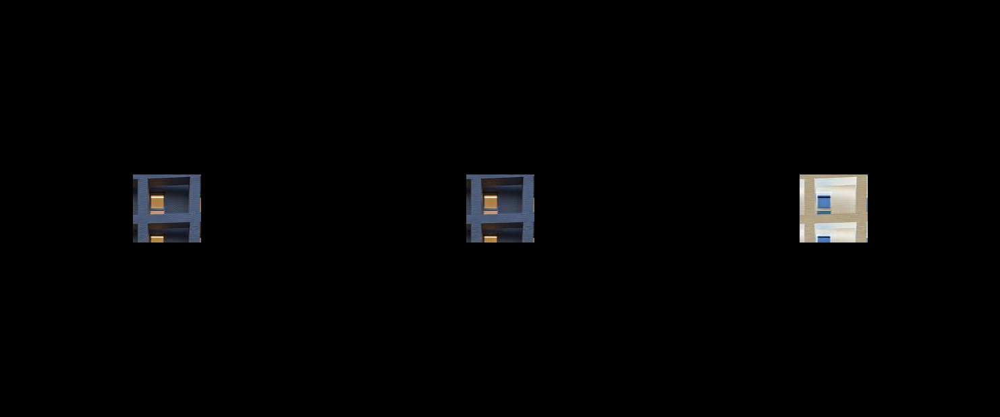

In [ ]:
#한 이미지의 비트와이즈 AND,OR,NOT 연산에 마스크 추가
andMask = cv2.bitwise_and(image1, image1, mask=maskImage2D)
orMask = cv2.bitwise_or(image1, image1, mask=maskImage2D)
notMask = cv2.bitwise_not(image1, mask=maskImage2D)

print("2D 마스크 효과 이미지")
mask_frame = cv2.hconcat([andMask,orMask,notMask])
cv2_imshow(mask_frame)

##04 마스크와 스레시홀딩을 활용한 이미지 합성

**04.1 알파 채널 마스크와 스레시홀딩을 사용한 이미지 합성**

png 파일의 알파 채널을 포함한 RGBA 이미지를 불러올 떄:

```
cv2.imread("image.png", cv2.IMREAD_UNCHANGED)
```

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/frame.png'
imagePath2 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/sea.jpg'

# 옵션을 붙여야 4채널(알파 채널 포함)로 읽어온다.
paperLayer = cv2.imread(imagePath1, cv2.IMREAD_UNCHANGED)
print(paperLayer.shape) # 그런데 채널이 3개뿐이네?
bgLayer = cv2.imread(imagePath2)

print("원본 이미지: PNG 포멧의 RGBA이미지와 JPG포멧의 RGB 이미지")
image_frame = cv2.hconcat([paperLayer[:,:,:3], bgLayer])
cv2_imshow(image_frame)


Output hidden; open in https://colab.research.google.com to view.

PNG 이미지의 알파값으로 만든 마스크와 반전마스크


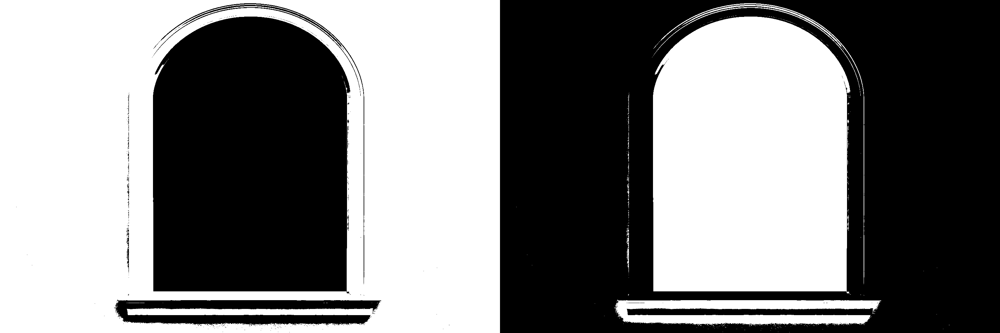

In [ ]:
#알파채널을 사용해서 마스크와 반전마스크 생성
# 현재 불러온 이미지는 알파채널이 없음
# _, mask = cv2.threshold(paperLayer[:,:,3],200,255,cv2.THRESH_BINARY)

# 3. 알파 채널 대신 흑백(Grayscale) 변환 후 밝기 기반 마스크 생성
# frame.png에서 배경이 되는 밝은 영역(흰색에 가까운 부분)을 찾아냅니다.
grayPaper = cv2.cvtColor(paperLayer, cv2.COLOR_BGR2GRAY)

# 문턱값(Threshold) 200을 기준으로 흰색 배경은 255(흰색), 물체는 0(검은색) 마스크 생성
_, mask = cv2.threshold(grayPaper, 200, 255, cv2.THRESH_BINARY)
invertedMask = cv2.bitwise_not(mask)

print("PNG 이미지의 알파값으로 만든 마스크와 반전마스크")
mask_frame = cv2.hconcat([mask,invertedMask])
cv2_imshow(mask_frame)


In [ ]:
#BRGA이미지를 BGR이미지로 변환
paperLayer = cv2.cvtColor(paperLayer, cv2.COLOR_BGRA2BGR)

#paperLayer에 마스크합성
paperImage = cv2.bitwise_and(paperLayer,paperLayer,mask=mask)
bgImage = cv2.bitwise_and(bgLayer,bgLayer,mask=invertedMask)
mergedImage = paperImage + bgImage

print("PNG 이미지의 알파값으로 만든 마스크를 적용한 종이이미지와 반전마스크를 적용한 배경 이미지의 합성")
mask_frame = cv2.hconcat([paperImage,bgImage,mergedImage])
cv2_imshow(mask_frame)

Output hidden; open in https://colab.research.google.com to view.

**04.2 ROI를 설정해 알파채널 이미지 합성하기**

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

imagePath1 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/boat.png'
imagePath2 ='/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/sea.jpg'
robotImage = cv2.imread(imagePath1, cv2.IMREAD_UNCHANGED)
nightImage = cv2.imread(imagePath2)

print(nightImage.shape)


cv2_imshow(robotImage)
cv2_imshow(nightImage)

Output hidden; open in https://colab.research.google.com to view.

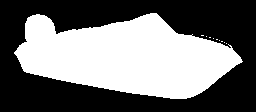

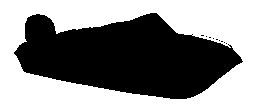

In [ ]:
#알파채널을 사용해서 로봇이미지의 마스크와 반전마스크 생성
ret, robotMask = cv2.threshold(robotImage[:,:,3],200,255,cv2.THRESH_BINARY)
invertedMask = cv2.bitwise_not(robotMask)
cv2_imshow(robotMask)
cv2_imshow(invertedMask)

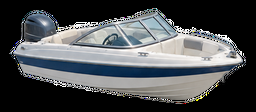

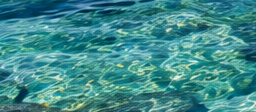

In [ ]:
#BGRA인 로봇이미지를 BGR컬러이미지로 변환 후 크기에 맞게 ROI 잘라내기
robotImage = cv2.cvtColor(robotImage, cv2.COLOR_BGRA2BGR)
height, width = robotImage.shape[:2]
ROI = nightImage[800:800+height,120:120+width]

cv2_imshow(robotImage)
cv2_imshow(ROI)

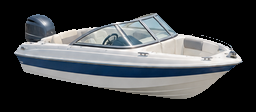

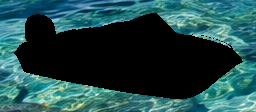

In [ ]:
#로봇 이미지에 마스크를, ROI 이미지에는 반전 마스크 적용
maskedRobotImage = cv2.bitwise_and(robotImage,robotImage,mask=robotMask)
maskedROIImage = cv2.bitwise_and(ROI,ROI,mask=invertedMask)

cv2_imshow(maskedRobotImage)
cv2_imshow(maskedROIImage)

In [ ]:
#로봇이미지와 ROI 이미지를 합성 후 밤하늘 이미지에 추가
robotROI = maskedRobotImage + maskedROIImage
nightImage[800:800+height,120:120+width] = robotROI

cv2_imshow(robotROI)
cv2_imshow(nightImage)

Output hidden; open in https://colab.research.google.com to view.

**04.3 HSV 컬러 범위로 스레시홀딩 후 이미지 마스킹하기**

RGB보다 HSV 컬러채널이 더 색 범위를 구하기 쉬움

- **Hue(색상)** 채널의 범위는 0°의 빨간색을 시작으로 가시광선 빛의 파장을 360° 원 형식으로 표현
- **Saturation(채도,선명함)** 채널의 범위는 특정한 색상의 가장 선명한 상태를 100%로 하고
무채색은 0%
- **Value(명도,밝기)** 채널의 범위는 가장 밝은 색상이 100%이고 검은색이 0%
- OpenCV는 **uint8 자료형으로 0부터 255 값**으로 색상과 채도, 명도 값을 표현  
  - **Hue(색상)**은 360°/2=180°로 **[0,179]** 사이 값으로 표현하고 180-255까지의 값은 **179**로 표현
  - **Saturation(채도)**는 0-100% 값을 **[0,255]**범위로 표현
  - **Value(명도**)는  0-100% 값을 **[0,255]**범위로 표현

<br>

HSV 컬러 색상의 범위를 지정하는 함수:
```
cv2.inRange(hsv, lowerValue, upperValuse)
```

In [ ]:
import cv2
import numpy as np

red = np.uint8([[[0,0,255]]])
yellow = np.uint8([[[0,255,255]]])
green = np.uint8([[[0,255,0]]])
blue = np.uint8([[[255,0,0]]])

hsv_red = cv2.cvtColor(red,cv2.COLOR_BGR2HSV)
hsv_yellow = cv2.cvtColor(yellow,cv2.COLOR_BGR2HSV)
hsv_green = cv2.cvtColor(green,cv2.COLOR_BGR2HSV)
hsv_blue = cv2.cvtColor(blue,cv2.COLOR_BGR2HSV)

print(hsv_red,hsv_yellow,hsv_green,hsv_blue)

[[[  0 255 255]]] [[[ 30 255 255]]] [[[ 60 255 255]]] [[[120 255 255]]]


In [ ]:
h,s,v = hsv_yellow[0,0,:]

lower_bound = [h-10,50,50]
upper_bound = [h+10,255,255]

print(lower_bound)
print(upper_bound)

[np.uint8(20), 50, 50]
[np.uint8(40), 255, 255]


**04.4 HSV 컬러필터 만들기**

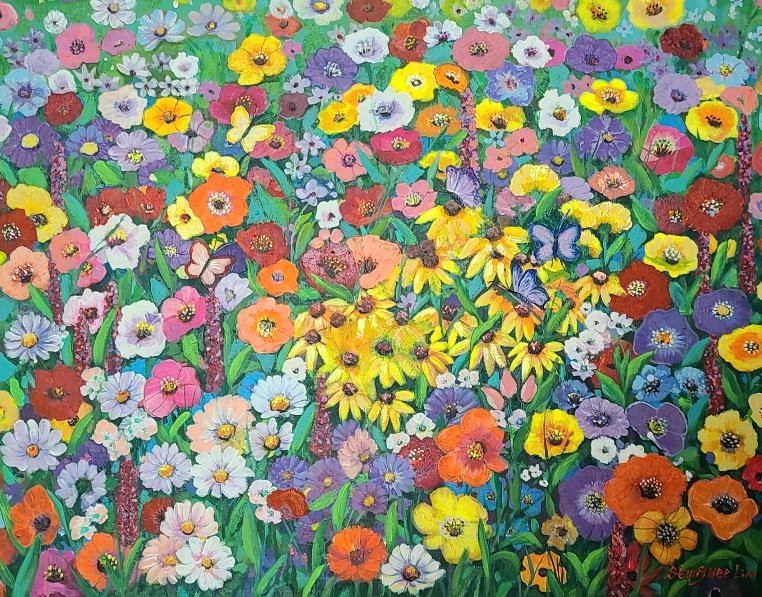

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

image = cv2.imread("/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/flowers.jpg")
cv2_imshow(image)


In [ ]:
#HSV 이미지로 변환
hsv = cv2.cvtColor(image,cv2.COLOR_BGR2HSV)

#색상별 영역 지정
blue1 = np.array([110, 50, 50])
blue2 = np.array([130, 255,255])

green1 = np.array([50, 50, 50])
green2 = np.array([70, 255, 255])

red1 = np.array([0,50,50])
red2 = np.array([10,255,255])
red3 = np.array([170,50,50])
red4 = np.array([179,255,255])

yellow1 = np.array([20,50,50])
yellow2 = np.array([40,255,255])

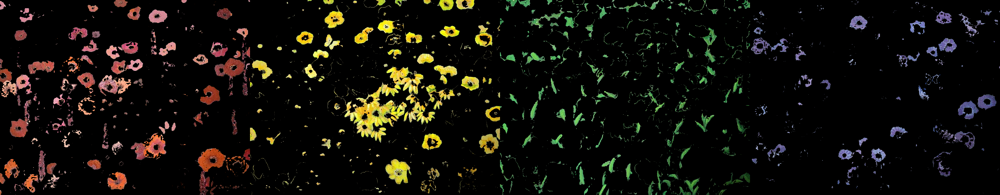

In [ ]:
#HSV 컬러 마스크 생성
mask_blue = cv2.inRange(hsv, blue1, blue2)
mask_green = cv2.inRange(hsv, green1, green2)
mask_red1 = cv2.inRange(hsv, red1, red2)
mask_red2 = cv2.inRange(hsv, red3, red4)
mask_yellow = cv2.inRange(hsv, yellow1, yellow2)


#색상별 마스크로 해당 색상만 추출
blueImage = cv2.bitwise_and(image, image, mask=mask_blue)
greenImage = cv2.bitwise_and(image, image, mask=mask_green)
yellowImage = cv2.bitwise_and(image, image, mask=mask_yellow)

redHalf1 = cv2.bitwise_and(image, image, mask=mask_red1)
redHalf2 = cv2.bitwise_and(image, image, mask=mask_red2)
redImage = cv2.bitwise_or(redHalf1, redHalf2)


color_frame = cv2.hconcat([redImage,yellowImage,greenImage,blueImage])
cv2_imshow(color_frame)

**04.5 HSV 채널 값을 슬라이더로 변경**

참고링크:
[Colab Forms](https://colab.research.google.com/notebooks/forms.ipynb)


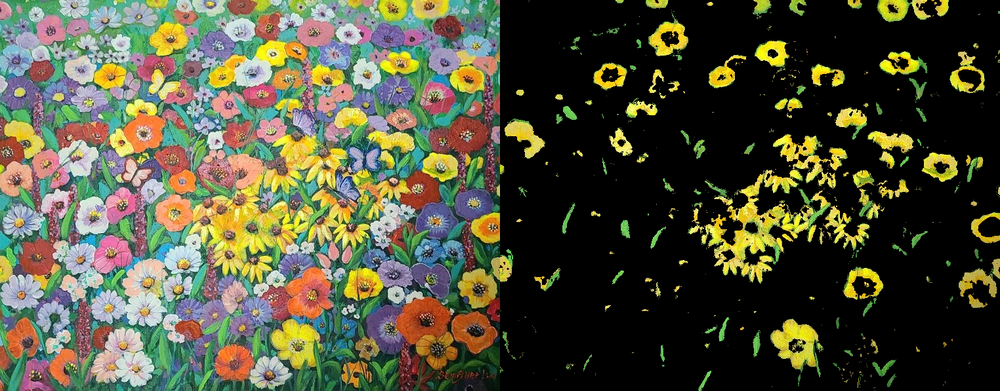

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

image = cv2.imread("/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/photos/flowers.jpg")

hueMin = 23 #@param {type:"slider", min:0, max:179, step:1}
satMin = 109 #@param {type:"slider", min:0, max:255, step:1}
valMin = 105 #@param {type:"slider", min:0, max:255, step:1}
hueMax = 59 #@param {type:"slider", min:0, max:179, step:1}
satMax = 255 #@param {type:"slider", min:0, max:255, step:1}
valMax = 255 #@param {type:"slider", min:0, max:255, step:1}

lower = np.array([hueMin, satMin, valMin])
upper = np.array([hueMax, satMax, valMax])

# Create HSV Image and threshold into a range.
hsvImage = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsvImage, lower, upper)
result = cv2.bitwise_and(image,image, mask=mask)

color_frame = cv2.hconcat([image,result])
cv2_imshow(color_frame)

In [ ]:
#구글 드라이브 마운트 하기
# from google.colab import drive
# drive.mount('/content/drive',force_remount=True)
!jupyter nbconvert --to markdown "/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/3강_이미지프로세싱기초2.ipynb"

Mounted at /content/drive
[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/3강_이미지프로세싱기초2.ipynb to markdown
[NbConvertApp] Support files will be in 3강_이미지프로세싱기초2_files/
[NbConvertApp] Making directory /content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/3강_이미지프로세싱기초2_files
[NbConvertApp] Writing 35847 bytes to /content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/3강_이미지프로세싱기초2.md
